# Part B — Customer Segmentation and Lapse Prediction

In [1]:
#  Imports and project paths

import os
os.environ["OMP_NUM_THREADS"] = "5"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score
)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

CLEAN = ROOT / "data" / "clean"
OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

required_files = [
    CLEAN / "customers_clean.csv",
    CLEAN / "orders_clean.csv"
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required Part A files were not found: " + ", ".join(missing_files)
    )

print("Project root:", ROOT)
print("Clean data folder:", CLEAN)
print("Outputs folder:", OUTPUTS)

Project root: C:\Users\ashmi\Instamart - customer - copilot
Clean data folder: C:\Users\ashmi\Instamart - customer - copilot\data\clean
Outputs folder: C:\Users\ashmi\Instamart - customer - copilot\outputs


In [2]:
# Load the cleaned Part A datasets

customers = pd.read_csv(CLEAN / "customers_clean.csv")
orders = pd.read_csv(CLEAN / "orders_clean.csv")

orders["order_ts"] = pd.to_datetime(orders["order_ts"], errors="coerce")

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("\nOrder status counts:")
display(orders["status"].value_counts().to_frame("Order_Count"))

Customers: (1200, 5)
Orders: (12309, 9)

Order status counts:


,Order_Count
status,
completed,11110
cancelled,1199


## RFM customer analysis

RFM represents:
- **Recency:** days since the customer's latest completed order.
- **Frequency:** number of distinct completed orders.
- **Monetary:** total amount spent on completed orders.

In [3]:
#  Build the RFM table

SNAPSHOT_DATE = pd.Timestamp("2025-10-01")

completed_orders = orders[
    (orders["status"] == "completed") &
    (orders["order_ts"] < SNAPSHOT_DATE)
].copy()

rfm = completed_orders.groupby("customer_id").agg(
    Last_Order_Date=("order_ts", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("order_amount", "sum")
).reset_index()

rfm["Recency"] = (SNAPSHOT_DATE - rfm["Last_Order_Date"]).dt.days
rfm = rfm[
    ["customer_id", "Recency", "Frequency", "Monetary", "Last_Order_Date"]
]

assert rfm["customer_id"].is_unique
assert rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()

rfm.to_csv(OUTPUTS / "customer_rfm.csv", index=False)

print("Completed orders:", len(completed_orders))
print("Customers in RFM table:", len(rfm))
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Completed orders: 11110
Customers in RFM table: 1175


,customer_id,Recency,Frequency,Monetary,Last_Order_Date
0,C0001,14,4,512.85,2025-09-16 08:07:21
1,C0002,28,7,4644.90,2025-09-02 13:33:13
2,C0003,7,22,3644.85,2025-09-23 16:55:36
3,C0004,0,5,369.00,2025-09-30 15:09:46
4,C0005,147,2,324.00,2025-05-06 21:44:20


,Recency,Frequency,Monetary
count,1175.00,1175.00,1175.00
mean,33.56,9.46,2552.06
std,38.43,8.01,2367.31
min,0.00,1.00,12.00
25%,6.00,3.00,505.45
50%,19.00,5.00,2286.50
75%,46.00,17.00,3751.52
max,180.00,33.00,14766.55


## K-Means customer segmentation

In [4]:
#  Standardise RFM features and compare cluster counts

rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

cluster_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    cluster_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(rfm_scaled, labels)
    })

cluster_results_df = pd.DataFrame(cluster_results)
display(cluster_results_df.round(4))

,K,Inertia,Silhouette_Score
0,2,1820.7606,0.4650
1,3,1268.2346,0.4452
2,4,743.0711,0.5255
3,5,617.3666,0.4805
4,6,503.1706,0.4819
5,7,408.4605,0.4163
6,8,366.5035,0.4123


In [5]:
#  Fit the final four-cluster model and profile the segments

FINAL_K = 4
kmeans_final = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
rfm["Cluster"] = kmeans_final.fit_predict(rfm_scaled)

segment_names = {
    0: "Occasional Customers",
    1: "Premium Customers",
    2: "Frequent Active Customers",
    3: "At-Risk Customers"
}
rfm["Segment"] = rfm["Cluster"].map(segment_names)

cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("customer_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)
cluster_profile["Segment"] = cluster_profile.index.map(segment_names)

customer_segments = rfm.merge(
    customers, on="customer_id", how="left", validate="one_to_one"
)

cluster_profile.to_csv(OUTPUTS / "cluster_profile.csv")
customer_segments.to_csv(OUTPUTS / "customer_segments.csv", index=False)

print("Customers assigned:", rfm["Cluster"].notna().sum())
display(cluster_profile)
print("\nSegment counts:")
display(customer_segments["Segment"].value_counts().to_frame("Customer_Count"))

Customers assigned: 1175


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Segment
Cluster,,,,,,
0,436,28.86,3.77,1057.62,701.72,Occasional Customers
1,138,24.12,6.77,7129.70,6610.02,Premium Customers
2,419,8.77,19.40,3410.02,3303.20,Frequent Active Customers
3,182,109.04,2.20,685.99,354.50,At-Risk Customers



Segment counts:


,Customer_Count
Segment,
Occasional Customers,436
Frequent Active Customers,419
At-Risk Customers,182
Premium Customers,138


PCA output shape: (1175, 2)
Variance explained by PC1: 63.43 %
Variance explained by PC2: 21.8 %
Total variance explained: 85.23 %


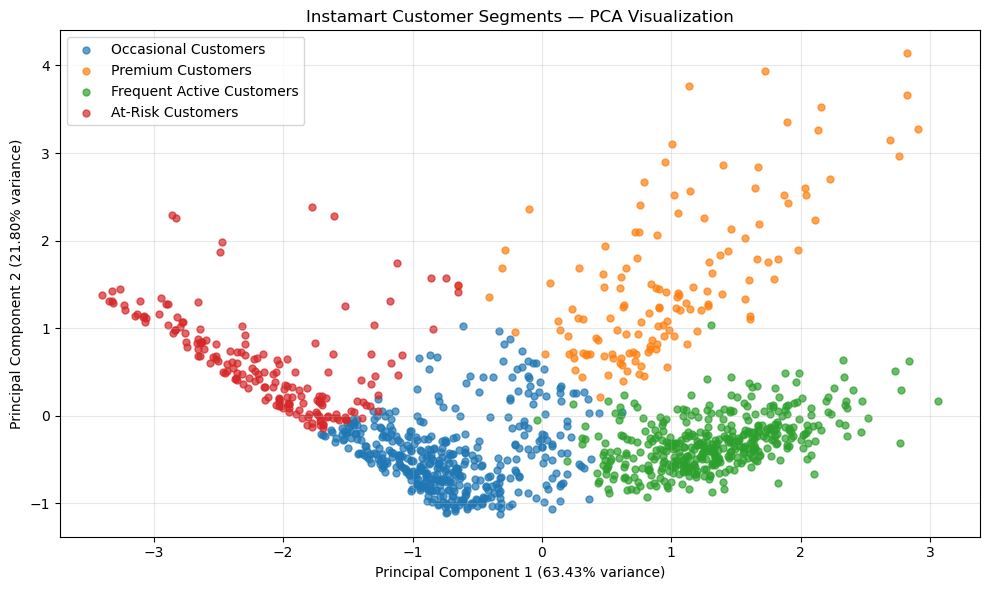

In [6]:
#  Visualise the four clusters with PCA

pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)
variance = pca.explained_variance_ratio_

print("PCA output shape:", rfm_pca.shape)
print("Variance explained by PC1:", round(variance[0] * 100, 2), "%")
print("Variance explained by PC2:", round(variance[1] * 100, 2), "%")
print("Total variance explained:", round(variance.sum() * 100, 2), "%")

plt.figure(figsize=(10, 6))
for cluster_id in sorted(rfm["Cluster"].unique()):
    mask = rfm["Cluster"] == cluster_id
    plt.scatter(
        rfm_pca[mask, 0],
        rfm_pca[mask, 1],
        label=segment_names[cluster_id],
        alpha=0.7,
        s=25
    )

plt.xlabel(f"Principal Component 1 ({variance[0] * 100:.2f}% variance)")
plt.ylabel(f"Principal Component 2 ({variance[1] * 100:.2f}% variance)")
plt.title("Instamart Customer Segments — PCA Visualization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Lapse prediction

The prediction cutoff is September 1, 2025.

- **Active (0):** at least one completed order during September 2025.
- **Lapsed (1):** no completed order during September 2025.

Only orders before September 1 are used to calculate model features. September orders are used only to create the target label.

In [7]:
#  Create historical features and the lapse target

CUTOFF_DATE = pd.Timestamp("2025-09-01")
SEPTEMBER_END = pd.Timestamp("2025-10-01")

historical_orders = orders[
    (orders["status"] == "completed") &
    (orders["order_ts"] < CUTOFF_DATE)
].copy()

september_orders = orders[
    (orders["status"] == "completed") &
    (orders["order_ts"] >= CUTOFF_DATE) &
    (orders["order_ts"] < SEPTEMBER_END)
].copy()

lapse_features = historical_orders.groupby("customer_id").agg(
    Last_Order_Date=("order_ts", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("order_amount", "sum"),
    Average_Order_Value=("order_amount", "mean")
).reset_index()

lapse_features["Recency"] = (
    CUTOFF_DATE - lapse_features["Last_Order_Date"]
).dt.days

september_customer_ids = set(september_orders["customer_id"].unique())
lapse_features["Lapsed"] = (
    ~lapse_features["customer_id"].isin(september_customer_ids)
).astype(int)

feature_columns = [
    "Recency", "Frequency", "Monetary", "Average_Order_Value"
]
lapse_data = lapse_features[
    ["customer_id"] + feature_columns + ["Lapsed"]
].copy()

assert lapse_data[feature_columns].notna().all().all()

print("Customers with historical purchases:", len(lapse_data))
print("Target counts (0 = Active, 1 = Lapsed):")
display(lapse_data["Lapsed"].value_counts().sort_index().to_frame("Customers"))
display(lapse_data.head())

Customers with historical purchases: 1156
Target counts (0 = Active, 1 = Lapsed):


,Customers
Lapsed,
0,713
1,443


,customer_id,Recency,Frequency,Monetary,Average_Order_Value,Lapsed
0,C0001,33,2,378.00,189.000000,0
1,C0002,22,6,3946.90,657.816667,0
2,C0003,1,20,3264.05,163.202500,0
3,C0004,42,3,272.25,90.750000,0
4,C0005,117,2,324.00,162.000000,1


In [8]:
#  Create a stratified train-test split

X = lapse_data[feature_columns].copy()
y = lapse_data["Lapsed"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training lapsed rate:", round(y_train.mean() * 100, 2), "%")
print("Testing lapsed rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 924
Testing rows: 232
Training lapsed rate: 38.31 %
Testing lapsed rate: 38.36 %


##  Model training and evaluation

In [9]:
#  Tune Logistic Regression and Random Forest

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

lr_search = GridSearchCV(
    lr_pipeline,
    {"classifier__C": [0.1, 1, 10]},
    scoring="f1",
    cv=5,
    n_jobs=1
)

rf_search = GridSearchCV(
    rf_pipeline,
    {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10],
        "classifier__min_samples_leaf": [1, 5]
    },
    scoring="f1",
    cv=5,
    n_jobs=1
)

lr_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)

print("Logistic Regression best parameters:", lr_search.best_params_)
print("Logistic Regression CV F1:", round(lr_search.best_score_, 4))
print("\nRandom Forest best parameters:", rf_search.best_params_)
print("Random Forest CV F1:", round(rf_search.best_score_, 4))

Logistic Regression best parameters: {'classifier__C': 10}
Logistic Regression CV F1: 0.7175

Random Forest best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Random Forest CV F1: 0.692


In [10]:
#  Evaluate both tuned models on the same test set

models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

evaluation_results = []
for model_name, model in models.items():
    predictions = model.predict(X_test)
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Lapsed_Class_F1": f1_score(y_test, predictions, pos_label=1)
    })

    print("=" * 55)
    print(model_name)
    print(classification_report(
        y_test, predictions,
        target_names=["Active (0)", "Lapsed (1)"],
        zero_division=0
    ))
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, predictions))

evaluation_df = pd.DataFrame(evaluation_results).sort_values(
    "Lapsed_Class_F1", ascending=False
).reset_index(drop=True)

display(evaluation_df.round(4))
evaluation_df.to_csv(OUTPUTS / "model_comparison.csv", index=False)

best_model_name = evaluation_df.loc[0, "Model"]
best_model = models[best_model_name]
best_test_f1 = float(evaluation_df.loc[0, "Lapsed_Class_F1"])

print("Selected model:", best_model_name)
print("Best test lapsed-class F1:", round(best_test_f1, 4))

Logistic Regression
              precision    recall  f1-score   support

  Active (0)       0.91      0.54      0.68       143
  Lapsed (1)       0.55      0.91      0.69        89

    accuracy                           0.68       232
   macro avg       0.73      0.72      0.68       232
weighted avg       0.77      0.68      0.68       232

Confusion matrix (rows = actual, columns = predicted):
[[77 66]
 [ 8 81]]
Random Forest
              precision    recall  f1-score   support

  Active (0)       0.83      0.62      0.71       143
  Lapsed (1)       0.57      0.80      0.66        89

    accuracy                           0.69       232
   macro avg       0.70      0.71      0.69       232
weighted avg       0.73      0.69      0.69       232

Confusion matrix (rows = actual, columns = predicted):
[[89 54]
 [18 71]]


,Model,Accuracy,Lapsed_Class_F1
0,Logistic Regression,0.6810,0.6864
1,Random Forest,0.6897,0.6636


Selected model: Logistic Regression
Best test lapsed-class F1: 0.6864


In [11]:
# Save and reload the selected model; inspect feature importance

MODEL_PATH = OUTPUTS / "lapse_model.joblib"
joblib.dump(best_model, MODEL_PATH)
loaded_model = joblib.load(MODEL_PATH)

original_predictions = best_model.predict(X_test)
reloaded_predictions = loaded_model.predict(X_test)
assert np.array_equal(original_predictions, reloaded_predictions)

classifier = best_model.named_steps["classifier"]
if hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
    importance_method = "Random Forest feature importance"
else:
    importance_values = np.abs(classifier.coef_[0])
    importance_method = "Absolute Logistic Regression coefficients"

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

display(feature_importance)
feature_importance.to_csv(OUTPUTS / "lapse_feature_importance.csv", index=False)

print("Importance method:", importance_method)
print("Model saved:", MODEL_PATH.exists())
print("Reloaded predictions match:", np.array_equal(
    original_predictions, reloaded_predictions
))
print("Required F1 >= 0.55:", best_test_f1 >= 0.55)

,Feature,Importance
1,Frequency,1.694332
3,Average_Order_Value,0.354553
2,Monetary,0.340579
0,Recency,0.060377


Importance method: Absolute Logistic Regression coefficients
Model saved: True
Reloaded predictions match: True
Required F1 >= 0.55: True


##  Retention list

The retention list is built once, from the held-out test customers who belong to the Premium Customers segment. They are ranked by predicted lapse probability, highest first. The file also records whether each customer actually lapsed in September, so the result can be checked against the test labels.

In [12]:
#  Create one consistent retention list (top 10 Premium test customers)

test_probabilities = loaded_model.predict_proba(X_test)[:, 1]
test_ids = lapse_data.loc[X_test.index, "customer_id"].to_numpy()
test_actual = y_test.reindex(X_test.index).to_numpy()

test_retention = pd.DataFrame({
    "customer_id": test_ids,
    "lapse_probability": test_probabilities,
    "actually_lapsed": test_actual.astype(int)
})

premium_ids = set(
    customer_segments.loc[
        customer_segments["Segment"] == "Premium Customers",
        "customer_id"
    ]
)

retention_list = (
    test_retention[test_retention["customer_id"].isin(premium_ids)]
    .sort_values("lapse_probability", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

RETENTION_PATH = OUTPUTS / "retention_list.csv"
retention_list.to_csv(RETENTION_PATH, index=False)

print("Retention list saved:", RETENTION_PATH.exists())
print("Premium test customers selected:", len(retention_list))
display(retention_list)

Retention list saved: True
Premium test customers selected: 10


,customer_id,lapse_probability,actually_lapsed
0,C1156,0.613799,0
1,C0133,0.612859,0
2,C0831,0.607747,0
3,C0060,0.604306,0
4,C0021,0.602558,0
5,C0942,0.595461,0
6,C1112,0.593222,0
7,C0862,0.586102,0
8,C0565,0.583968,1
9,C1008,0.574806,0


In [13]:
#  Validate Part B outputs

saved_rfm = pd.read_csv(OUTPUTS / "customer_rfm.csv")
saved_segments = pd.read_csv(OUTPUTS / "customer_segments.csv")
saved_retention = pd.read_csv(OUTPUTS / "retention_list.csv")
saved_importance = pd.read_csv(OUTPUTS / "lapse_feature_importance.csv")

checks = {
    "RFM output exists and has 1,175 customers": (
        len(saved_rfm) == 1175 and saved_rfm["customer_id"].is_unique
    ),
    "Four customer segments were created": (
        saved_segments["Segment"].nunique() == 4
    ),
    "All RFM values are present": (
        saved_rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()
    ),
    "Every customer has a segment": (
        saved_segments["Segment"].notna().all()
    ),
    "Selected model file exists": MODEL_PATH.exists(),
    "Model reload predictions match": np.array_equal(
        original_predictions, reloaded_predictions
    ),
    "Test F1 meets the 0.55 threshold": best_test_f1 >= 0.55,
    "Retention customer IDs are unique": (
        saved_retention["customer_id"].is_unique
    ),
    "Retention probabilities are valid": (
        saved_retention["lapse_probability"].between(0, 1).all()
    ),
    "Retention list is sorted highest probability first": (
        saved_retention["lapse_probability"].is_monotonic_decreasing
    ),
    "Retention list contains only Premium test customers": (
        set(saved_retention["customer_id"]).issubset(premium_ids)
    ),
    "Feature importance output has four features": (
        len(saved_importance) == len(feature_columns)
    )
}

for name, passed in checks.items():
    print(("PASSED" if passed else "FAILED") + ": " + name)

assert all(checks.values()), "One or more Part B validation checks failed."

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("ALL PART B CHECKPOINTS PASSED")

PASSED: RFM output exists and has 1,175 customers
PASSED: Four customer segments were created
PASSED: All RFM values are present
PASSED: Every customer has a segment
PASSED: Selected model file exists
PASSED: Model reload predictions match
PASSED: Test F1 meets the 0.55 threshold
PASSED: Retention customer IDs are unique
PASSED: Retention probabilities are valid
PASSED: Retention list is sorted highest probability first
PASSED: Retention list contains only Premium test customers
PASSED: Feature importance output has four features

Passed: 12 / 12
ALL PART B CHECKPOINTS PASSED


##  Results and output files

The original notebook's recorded reference results were:
- 1,175 customers in the RFM table.
- Four K-Means customer segments.
- PCA explained approximately 85.23% of the RFM variance with two components.
- The original Logistic Regression test F1-score for the lapsed class was 0.6864; Random Forest scored 0.6636.
- The original retention-list description specified the top 10 Premium Customers in the test set, ordered by predicted lapse probability.


### Limitations
The model is trained and tested on synthetic data. The retention list is a retrospective demonstration because its Premium segment filter uses the full RFM period. Model performance should not be interpreted as a guarantee of future customer behaviour.